# Iris Flower Classification 🌸

An end-to-end **machine learning classification project** using the classic Iris dataset.

### Project goal
Predict the iris species — **setosa, versicolor, or virginica** — from sepal and petal measurements.

### What this notebook covers
- Data loading and quality checks
- Exploratory data analysis and visualization
- Stratified train/test splitting
- Leakage-safe preprocessing with scikit-learn `Pipeline`
- Four classical classification models
- Test-set evaluation and confusion matrices
- Stratified 5-fold cross-validation
- Model comparison and an example prediction

The experiment is intentionally simple and reproducible, making it a compact demonstration of a complete supervised-learning workflow.


## 1. Imports and setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
%matplotlib inline
RANDOM_STATE = 42

## 2. Load the dataset

In [2]:
iris = load_iris()
feature_names = iris.feature_names
target_names = list(iris.target_names)

df = pd.DataFrame(iris.data, columns=feature_names)
df["target"] = iris.target
df["species"] = df["target"].map(dict(enumerate(target_names)))

print(f"Shape: {df.shape}")
df.head()

Shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


The Iris dataset contains **150 observations**, four numeric features, and three target classes.

The four predictors are sepal length, sepal width, petal length, and petal width.

## 3. Data quality checks

In [3]:
print("Missing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass distribution:")
print(df["species"].value_counts())

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Duplicate rows: 1

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


There is one duplicate observation in the raw dataset. Because it is an exact duplicate, it is removed before modeling.

The classes remain nearly balanced after removal, so accuracy is a reasonable primary metric for this small demonstration.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (149, 6)


## 4. Exploratory Data Analysis

In [5]:
df[feature_names].describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,149.00,149.00,149.00,149.00
mean,5.84,3.06,3.75,1.19
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.30,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


### Feature distributions

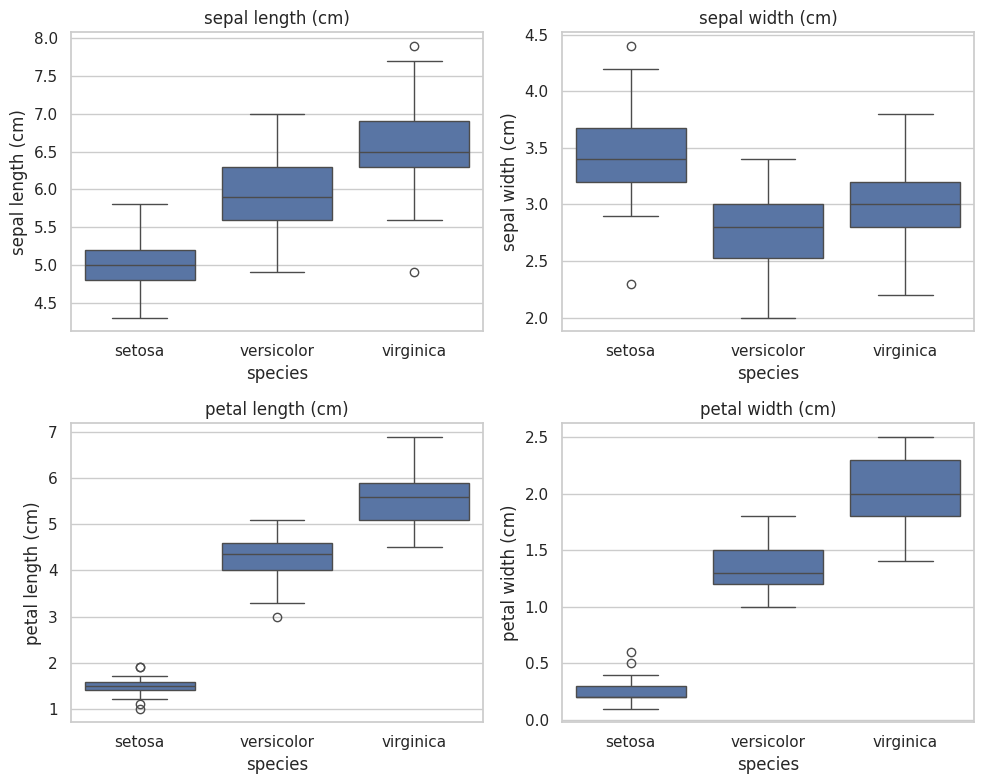

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, feature in zip(axes.ravel(), feature_names):
    sns.boxplot(data=df, x="species", y=feature, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.savefig("assets/feature_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

The petal measurements show noticeably stronger separation between species than the sepal measurements.

### Pairwise relationships

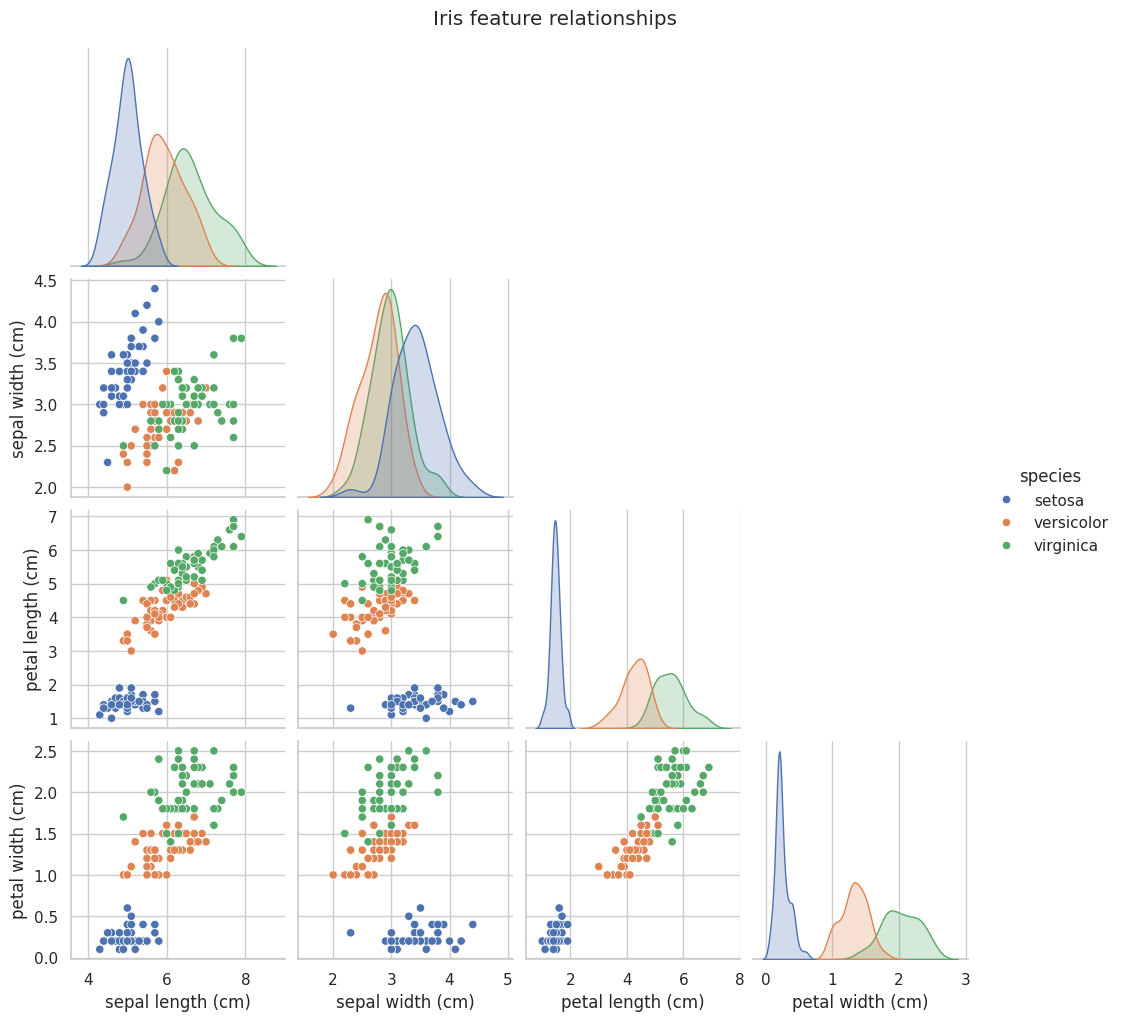

In [7]:
g = sns.pairplot(df, vars=feature_names, hue="species", corner=True)
g.fig.suptitle("Iris feature relationships", y=1.02)
g.fig.savefig("assets/pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

The pairplot shows a clear separation of **setosa**. The main overlap is between **versicolor** and **virginica**, especially in some sepal measurements.

### Correlation between numeric features

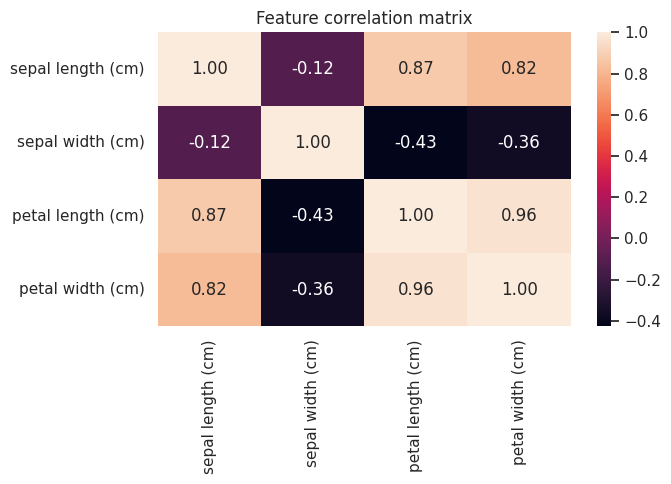

In [8]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[feature_names].corr(), annot=True, fmt=".2f")
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.savefig("assets/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Petal length and petal width are strongly correlated. This is useful context for interpreting the model results, but correlation alone is not used as a feature-selection rule here.

## 5. Train/test split

In [9]:
X = df[feature_names]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 119
Test samples: 30


A **stratified 80/20 split** keeps the class proportions similar between training and test sets. The test set is held out until final evaluation.

## 6. Build leakage-safe model pipelines

Scaling is included inside a scikit-learn `Pipeline` for Logistic Regression and KNN. This matters because, during cross-validation, the scaler must be fitted separately inside each training fold rather than on the full dataset.

Tree-based models do not require feature scaling, so they are used without a scaler.

In [10]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=200, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

for name, model in models.items():
    model.fit(X_train, y_train)

print(f"Trained {len(models)} models.")

Trained 4 models.


## 7. Evaluate on the held-out test set

In [11]:
test_results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    test_results.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, y_pred)
    })
    print(f"\n{'=' * 60}\n{name}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))


Logistic Regression
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


KNN
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


Decision Tree
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90    


Random Forest
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



### Confusion matrices

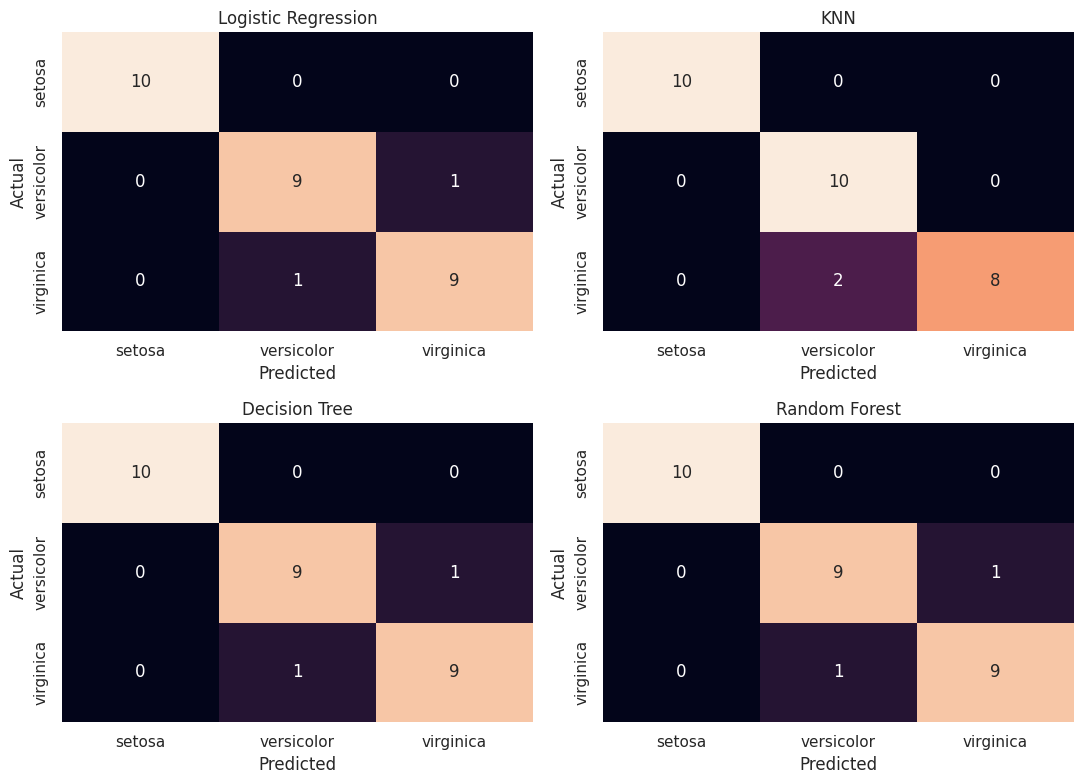

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cbar=False,
                xticklabels=target_names, yticklabels=target_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("assets/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

The confusion matrices make it easier to see which species are being confused. In this split, the difficult boundary is primarily between **versicolor** and **virginica**, while setosa is well separated.

## 8. 5-fold cross-validation

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

comparison = []
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    fitted_model = models[name]
    test_pred = fitted_model.predict(X_test)
    comparison.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "CV Mean Accuracy": cv_scores.mean(),
        "CV Std": cv_scores.std()
    })

comparison_df = pd.DataFrame(comparison).sort_values(
    ["CV Mean Accuracy", "CV Std"], ascending=[False, True]
).reset_index(drop=True)
comparison_df.round(4)

,Model,Test Accuracy,CV Mean Accuracy,CV Std
0,Logistic Regression,0.9333,0.9656,0.0506
1,KNN,0.9333,0.9572,0.0476
2,Random Forest,0.9333,0.9402,0.0649
3,Decision Tree,0.9333,0.9319,0.0591


### Model comparison summary

The table below brings the held-out test accuracy and 5-fold cross-validation results together in one place. The cross-validation score is computed only on the training portion, while the test set remains held out for final evaluation.

In [ ]:
comparison_df.style.format({
    "Test Accuracy": "{:.3f}",
    "CV Mean Accuracy": "{:.3f}",
    "CV Std": "{:.3f}"
})

Cross-validation provides a more stable estimate than relying on one 30-sample test set. The table above reports the mean and standard deviation across five stratified folds of the **training data**.

Use these numbers as an experiment-specific comparison, not as a universal statement that one algorithm is always better.

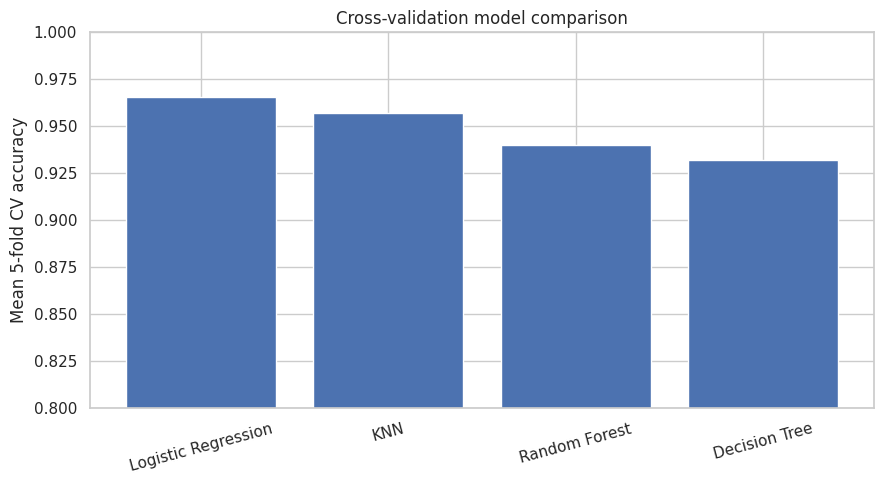

In [14]:
plt.figure(figsize=(9, 5))
plt.bar(comparison_df["Model"], comparison_df["CV Mean Accuracy"])
plt.ylim(0.8, 1.0)
plt.ylabel("Mean 5-fold CV accuracy")
plt.title("Cross-validation model comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("assets/cv_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Experiment conclusion

In [15]:
best_row = comparison_df.iloc[0]
print(f"Highest CV mean in this experiment: {best_row['Model']}")
print(f"CV mean accuracy: {best_row['CV Mean Accuracy']:.3f}")
print(f"CV standard deviation: {best_row['CV Std']:.3f}")
print(f"Test accuracy: {best_row['Test Accuracy']:.3f}")

Highest CV mean in this experiment: Logistic Regression
CV mean accuracy: 0.966
CV standard deviation: 0.051
Test accuracy: 0.933


### Takeaways

- Petal length and petal width provide strong visual separation between the classes.
- Setosa is substantially easier to separate than the other two species.
- All four classical classifiers perform strongly on this small dataset.
- The held-out test set contains only 30 observations, so identical test accuracy can occur across models.
- Cross-validation gives additional evidence about performance across different training/validation splits.
- The model with the highest CV mean above is the **best-performing model only within this specific experiment**; the result is not a general algorithm ranking.

## 10. Example prediction

In [16]:
# Example flower measurements: sepal length, sepal width, petal length, petal width
example = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=feature_names)

# Use the model with the highest CV mean from this experiment
selected_model_name = comparison_df.loc[0, "Model"]
selected_model = models[selected_model_name]
predicted_class = selected_model.predict(example)[0]

print("Selected model:", selected_model_name)
print("Predicted species:", target_names[predicted_class])

Selected model: Logistic Regression
Predicted species: setosa


## 11. Possible next steps

- Hyperparameter tuning with `GridSearchCV` or `RandomizedSearchCV`
- Compare additional classifiers
- Explore feature selection
- Add ROC/AUC analysis
- Save the trained model with `joblib`
- Build a small Streamlit interface for interactive predictions